In [ ]:
import sys
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

project_root = Path.cwd().resolve()
if project_root.name == "notebooks":
    project_root = project_root.parent

if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

In [3]:
results_csv = project_root / "results" / "streaming_benchmark_results.csv"
figures_dir = project_root / "results" / "figures"
figures_dir.mkdir(parents=True, exist_ok=True)

if not results_csv.exists():
    raise FileNotFoundError(
        f"The file does not exist at: {results_csv}\n"
        f"Please run the experiments first using:\n"
        "python run_experiments.py"
    )

In [4]:
df = pd.read_csv(results_csv)

In [5]:
plt.style.use('seaborn-v0_8-paper')
plt.rcParams.update({'font.size': 12, 'figure.autolayout': True})

plt.figure(figsize=(9, 4.5))
palette = {
    "Fixed-Window": "#7f7f7f", 
    "ACI": "#1f77b4", 
    "ERAPS": "#ff7f0e", 
    "MAC-Drift (Ours)": "#2ca02c"
}

<Figure size 900x450 with 0 Axes>

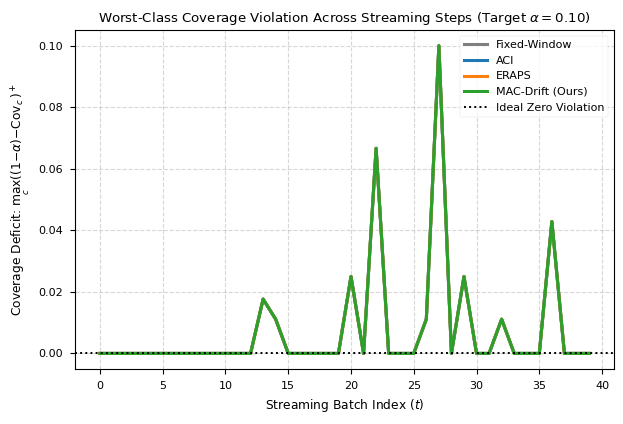

In [6]:
sns.lineplot(
    data=df, 
    x="step", 
    y="max_class_violation", 
    hue="method", 
    palette=palette,
    lw=2.2
)

plt.axhline(0.0, color='black', linestyle=':', label="Ideal Zero Violation")
plt.title(r"Worst-Class Coverage Violation Across Streaming Steps (Target $\alpha=0.10$)")
plt.xlabel(r"Streaming Batch Index ($t$)")
plt.ylabel(r"Coverage Deficit: $\max_c ((1 - \alpha) - \mathrm{Cov}_c)^+$")
plt.legend(frameon=True)
plt.grid(True, linestyle='--', alpha=0.5)

In [7]:
output_fig2 = figures_dir / "fig2_mondrian_violations.pdf"
plt.savefig(output_fig2, dpi=300)
plt.show()

print(f"[✓] Figure saved to: {output_fig2}")

<Figure size 640x440 with 0 Axes>

[✓] Figure saved to: D:\Development\projects for master\Paper researcher\MAC Drift Mondrian Adaptive Conformal Inference for Drifting Malware Streams\results\figures\fig2_mondrian_violations.pdf
